In [8]:
# Built-in modules
import math

# Imports from Qiskit
from qiskit import QuantumCircuit
from qiskit.circuit.library import grover_operator, MCMTGate, ZGate

# Imports from qiskit-ibm-runtime
from qiskit_ibm_runtime import QiskitRuntimeService


def grover_oracle(marked_states):
    """Build a Grover oracle for multiple marked states
[]
    Here we assume all input marked states have the same number of bits

    Parameters:
        marked_states (str or list): Marked states of oracle

    Returns:
        QuantumCircuit: Quantum circuit representing Grover oracle
    """
    if not isinstance(marked_states, list):
        marked_states = [marked_states]
    # Compute the number of qubits in circuit
    num_qubits = len(marked_states[0])

    qc = QuantumCircuit(num_qubits)
    # Mark each target state in the input list
    for target in marked_states:
        # Flip target bit-string to match Qiskit bit-ordering
        rev_target = target[::-1]
        # Find the indices of all the '0' elements in bit-string
        zero_inds = [
            ind
            for ind in range(num_qubits)
            if rev_target.startswith("0", ind)
        ]
        # Add a multi-controlled Z-gate with pre- and post-applied X-gates (open-controls)
        # where the target bit-string has a '0' entry
        if zero_inds:
            qc.x(zero_inds)
        qc.compose(MCMTGate(ZGate(), num_qubits - 1, 1), inplace=True)
        if zero_inds:
            qc.x(zero_inds)
    return qc

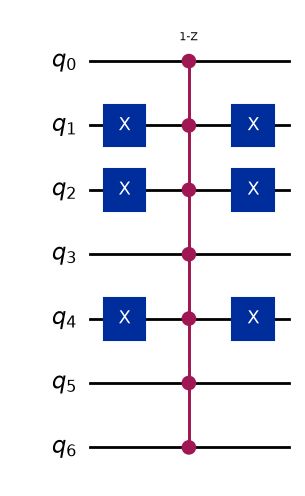

In [9]:
marked_states = ["1101001"]

oracle = grover_oracle(marked_states)

grover_op = grover_operator(oracle)

oracle.draw(output="mpl", style="iqp")

In [10]:
# Theoretical optimal number of Grover iterations
N = 2 ** grover_op.num_qubits
M = len(marked_states)

optimal_num_iterations = math.floor(
    math.pi / (4 * math.asin(math.sqrt(M / N)))
)

print("Theoretical optimal iterations:", optimal_num_iterations)

Theoretical optimal iterations: 8


In [11]:
def build_grover_circuit(iterations):
    qc = QuantumCircuit(grover_op.num_qubits)

    # Initial superposition
    qc.h(range(grover_op.num_qubits))

    # Grover iterations
    for _ in range(iterations):
        qc.compose(grover_op, inplace=True)

    qc.measure_all()

    return qc

In [12]:
service = QiskitRuntimeService()

backend = service.backend(name="ibm_fez")

In [13]:
from qiskit import generate_preset_pass_manager, transpile
from qiskit_ibm_runtime import SamplerV2 as Sampler

shots = 10_000

qc = build_grover_circuit(optimal_num_iterations)

pm = generate_preset_pass_manager(optimization_level=3, backend=backend)

isa_circuit = pm.run(qc)

sampler = Sampler(mode=backend)

sampler.options.dynamical_decoupling.enable = True
sampler.options.dynamical_decoupling.sequence_type = "XpXm" 

# Careful here: you're using compute minutes

In [14]:
job = sampler.run([isa_circuit])

In [15]:
result = job.result()
dist = result[0].data.meas.get_counts()

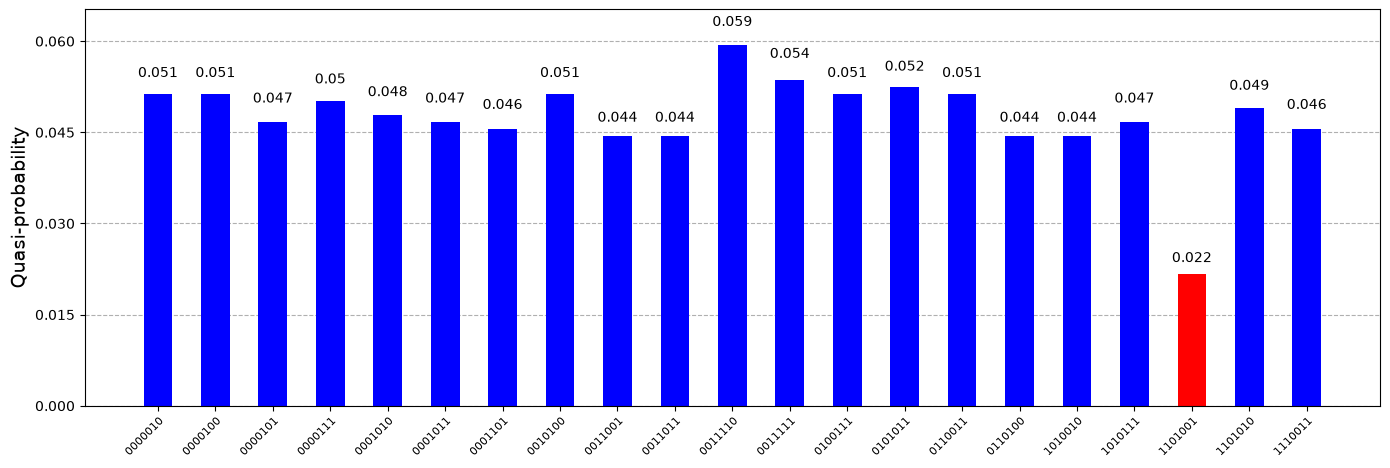

<Figure size 640x480 with 0 Axes>

In [16]:
import matplotlib.pyplot as plt
from qiskit.visualization import plot_distribution

# %matplotlib inline

# Bitstrings that must appear in red
red_states = marked_states

# Get the 20 most frequent outcomes
top_20 = dict(sorted(dist.items(), key=lambda item: item[1], reverse=True)[:20])

# Force all red states into the selection
for state in red_states:
    if state in dist:
        top_20[state] = dist[state]

# Plot the selected outcomes
fig = plot_distribution(top_20, figsize=(14, 5), color='blue')

# Color the specified states red
ax = fig.axes[0]
for bar, label in zip(ax.patches, [tick.get_text() for tick in ax.get_xticklabels()]):
    if label in red_states:
        bar.set_facecolor('red')

ax.tick_params(axis='x', labelrotation=45, labelsize=8)
plt.tight_layout()
display(fig)
plt.close(fig)

In [19]:
from pathlib import Path

output_dir = Path("figures")
output_dir.mkdir(parents=True, exist_ok=True)

# Plot the selected outcomes
fig = plot_distribution(dist, figsize=(200, 5), color='blue')

# Color the specified states red
ax = fig.axes[0]
for bar, label in zip(ax.patches, [tick.get_text() for tick in ax.get_xticklabels()]):
    if label in marked_states:
        bar.set_facecolor('red')

fig.savefig(output_dir / "dist_1.png", dpi=300, bbox_inches="tight")